# kNDVI short-term trajectories

## Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

## Paths and Run selection

In [5]:
# Local inputs and figure settings
PROJECT = Path.home() / "OneDrive" / "Documents" / "Master Thesis"
REPO = PROJECT / "ARCEME-Vegetation-Recovery"
SOURCE_DIR = PROJECT / "data" / "final_analysis" / "test_essential"
METRICS_FILE = REPO / "evaluation" / "analysis_data" / "metrics_detail.csv"
OUTPUT =  REPO / "evaluation" / "paper_figures" / "final_plots" / "lead_time_analysis"

CONFIGURATION = "SGEDConvLSTM RGB+NIR"
SPLIT, FOLD = "holdout", -1
MODEL_CONTEXT, N_CONTEXT = 30, 5
VEG_ONLY = True          
SAVE_FIGURES = False

TIME_DIM= "time_sentinel_2_l2a"

## Load Holdout and eligibility information

In [3]:
data = pd.read_csv(METRICS_FILE)
run = data.loc[
    data["configuration"].eq(CONFIGURATION) & data["split"].eq(SPLIT)
    & data["fold"].eq(FOLD) & data["landcover"].eq("all") & data["approach"].eq("Model")
]
events = run.loc[run["scope"].eq("overall")].set_index("cube_id", verify_integrity=True)
rules = run.loc[run["scope"].eq("step")].set_index(["cube_id", "step"], verify_integrity=True)
FUTURE = np.sort(rules.index.get_level_values("step").unique().to_numpy(dtype=int))
STEPS = np.r_[np.arange(1 - N_CONTEXT, 1), FUTURE]
print(f"{CONFIGURATION} · {len(events)} Cubes · {len(FUTURE)} Forecast-Schritte")

SGEDConvLSTM RGB+NIR · 26 Cubes · 6 Forecast-Schritte


## Get data from cubes and forecast tensors

In [6]:
def read_cube(cube_id, tensor_path):
    records = []

    def add(step, curve, pixels, eligible):
        n = pixels.size
        total = pixels.sum(dtype=np.float64)
        # SD der Pixel in diesem Cube an diesem Schritt; keine Balken bei <2 Pixeln.
        sd = pixels.std(dtype=np.float64, ddof=0) if n > 1 else np.nan
        records.append((cube_id, step, curve, total, n, eligible, sd))

    criteria = rules.loc[cube_id].loc[FUTURE]
    with xr.open_zarr(SOURCE_DIR / f"{cube_id}_postprocessed.zarr", chunks=None) as src:
        cutoff = pd.Timestamp(src.attrs["precip_end_date"])
        ctx = src.sel({TIME_DIM: slice(None, cutoff)}).tail({TIME_DIM: MODEL_CONTEXT})
        if ctx.sizes[TIME_DIM] != MODEL_CONTEXT or pd.Timestamp(ctx[TIME_DIM].values[-1]) != cutoff:
            raise ValueError(f"{cube_id}: Kontext stimmt nicht mit dem Cutoff überein.")
        veg = ctx.isel({TIME_DIM: -1})["is_veg"].transpose("y", "x").values > 0.5
        n_veg = int(veg.sum())
        masks = ctx["target_mask"].transpose(TIME_DIM, "y", "x").values > 0.5
        has_ref = masks.any(axis=0)
        if N_CONTEXT:
            frames = ctx["kNDVI"].tail({TIME_DIM: N_CONTEXT}).transpose(TIME_DIM, "y", "x").values
            threshold = criteria.iloc[0]
            for step, y, mask in zip(range(1 - N_CONTEXT, 1), frames, masks[-N_CONTEXT:]):
                ok = veg & mask & np.isfinite(y)
                n = int(ok.sum())
                eligible = n_veg > 0 and n >= threshold.min_count and n / n_veg >= threshold.min_coverage
                add(step, "observed", y[ok], eligible)

    with xr.open_zarr(tensor_path, chunks=None) as ds:
        if ds.sizes["time"] != len(FUTURE):
            raise ValueError(f"{cube_id}: unerwartete Forecast-Länge.")
        y, p, b, target_mask = [
            ds[k].transpose("time", "y", "x").values for k in ("true", "pred", "base", "mask")
        ]

    for t, step in enumerate(FUTURE):
        ok = veg & (target_mask[t] > 0.5) & np.isfinite(y[t])
        n = int(ok.sum())
        gate = criteria.loc[step]
        if n != gate.n_valid or not (np.isfinite(p[t][ok]).all() and np.isfinite(b[t][ok]).all()):
            raise ValueError(f"{cube_id}, +{step}: Tensoren passen nicht zur Auswertungsmaske.")
        for curve, frame in [("observed", y[t]), ("predicted", p[t]), ("persistence", b[t])]:
            add(step, curve, frame[ok], gate.eligible_errors)

        # Ausschluss des Null-Fallbacks nur dort, wo eine reale Kontextreferenz nötig ist.
        paired = ok & has_ref
        reference = b[t][paired]
        add(step, "base_paired", reference, gate.eligible_errors)
        # Erst pro Pixel subtrahieren, dann Mittel und SD der Änderungen berechnen.
        for curve, frame in [("delta_obs", y[t]), ("delta_pred", p[t])]:
            change = np.subtract(frame[paired], reference, dtype=np.float64)
            add(step, curve, change, gate.eligible_errors)

        full_ref = has_ref & np.isfinite(p[t]) & np.isfinite(b[t])
        if VEG_ONLY:
            full_ref &= veg

        change = np.subtract(p[t][full_ref], b[t][full_ref], dtype=np.float64)
        add(step, "delta_pred_all", change, True)

        for curve, frame in [("predicted_all", p[t]), ("persistence_all", b[t])]:
            full = np.isfinite(frame)
            if VEG_ONLY:
                full &= veg
            add(step, curve, frame[full], True)
    return records


rows = [row for cube_id, event in events.iterrows() for row in read_cube(cube_id, event.tensor_path)]
detail = pd.DataFrame(rows, columns=["cube_id", "step", "curve", "total", "n_pixels", "eligible", "spatial_sd"])
detail["cube_mean"] = detail["total"] / detail["n_pixels"].replace(0, np.nan)

## Plot Function

In [7]:
def plot_panels(table, *, cube_weighted=False, extra=(), error=None, error_for=(),
                show_persistence=True, background=None, fig_name=None):
    fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")

    def series(key, steps):
        return table.loc[table["curve"].eq(key)].set_index("step").reindex(steps)

    def line(ax, steps, key, label, color, style):
        g = series(key, steps)
        mean = g["mean"].to_numpy(dtype=float)
        if key.endswith("_all"):
            ns = g.loc[FUTURE, "n_cubes"].fillna(0).astype(int)
            n_text = str(ns.iloc[0]) if ns.nunique() == 1 else "/".join(map(str, ns))
            domain = "all vegetation pixels" if VEG_ONLY else "all pixels"
            label += f" ({domain}; n={n_text})"
        draw_error = cube_weighted and error is not None and key in error_for
        if draw_error:
            label += f" ±1 {error.upper()}"
        ax.plot(steps, mean, style, color=color, label=label, zorder=3,
                alpha=0.65 if key in {"predicted_all", "delta_pred_all"} else 1.0)
        if draw_error:
            spread = g["sd"].where(g["n_cubes"] > 1)
            if error == "se":
                spread = spread / np.sqrt(g["n_cubes"])
            spread = spread.to_numpy(dtype=float)
            if key in ("observed", "delta_obs"):
                ax.errorbar(steps, mean, yerr=spread, fmt="none", ecolor=color, lw=1, capsize=3)
            else:
                ax.fill_between(steps, mean-spread, mean+spread, color=color, alpha=0.15, lw=0)

    if background is not None:
        for _, group in background.groupby("cube_id"):
            g = group.pivot(index="step", columns="curve", values="cube_mean").reindex(STEPS)
            for key, color, ls in [("observed", "#0072B2", "-"), ("predicted", "#D55E00", "--")]:
                a.plot(STEPS, g[key], ls=ls, lw=0.9, alpha=0.22, color=color, zorder=1)

    suffix = " (observed pixels)" if cube_weighted else ""
    line(a, STEPS, "observed", "Observed", "#0072B2", "o-")
    line(a, FUTURE, "predicted", "Predicted" + suffix, "#D55E00", "s--")
    if show_persistence:
        if cube_weighted:
            line(a, FUTURE, "persistence", "Persistence" + suffix, "#707070", "^:")
        else:
            line(a, FUTURE, "base_paired", "Persistence (paired)", "#707070", "^:")
    for key in extra:
        if key == "predicted_all":
            line(a, FUTURE, key, "Predicted", "#036C11", "x--")
        elif key == "persistence_all":
            line(a, FUTURE, key, "Persistence", "#707070", "-")
    if N_CONTEXT:
        a.axvline(0.5, color="#C44E52" if cube_weighted else "0.5", ls="--", lw=1)
    a.set(title="A   Absolute kNDVI", ylabel="Mean kNDVI")

    b.axhline(0, color="#707070", ls=":", label="Persistence")
    line(b, FUTURE, "delta_obs", "Observed − persistence", "#0072B2", "o-")
    line(b, FUTURE, "delta_pred", "Predicted − persistence", "#D55E00", "s--")
    if "predicted_all" in extra:
        line(b, FUTURE, "delta_pred_all", "Predicted − persistence",
             "#036C11", "x--")
    b.set(title="B   Change from persistence", ylabel="Mean ΔkNDVI")

    for ax, steps, key in [(a, STEPS, "observed"), (b, FUTURE, "delta_obs")]:
        g = series(key, steps)
        if cube_weighted:
            counts = [f"({int(n)})" for n in g["n_cubes"].fillna(0)]
            xlabel = "Forecast step\n(number of contributing cubes)"
        else:
            counts = [f"{n/1e6:.1f}" for n in g["n_pixels"].fillna(0)]
            xlabel = "Forecast step \n(valid pixels, millions)"
        ax.set_xticks(steps, [f"{s:+d}\n{n}" if s else f"0\n{n}" for s, n in zip(steps, counts)])
        ax.set_xlabel(xlabel)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", alpha=0.25)
        ax.legend(frameon=False, fontsize=7)
    if SAVE_FIGURES:
        OUTPUT.mkdir(parents=True, exist_ok=True)
        name = "cube" if cube_weighted else "pixel"
        fig.savefig(OUTPUT / f"kndvi_{name}_weighted_panels_AB{fig_name}.png", dpi=300, bbox_inches="tight")
    plt.show()
    return fig

## Pixel weighted analysis

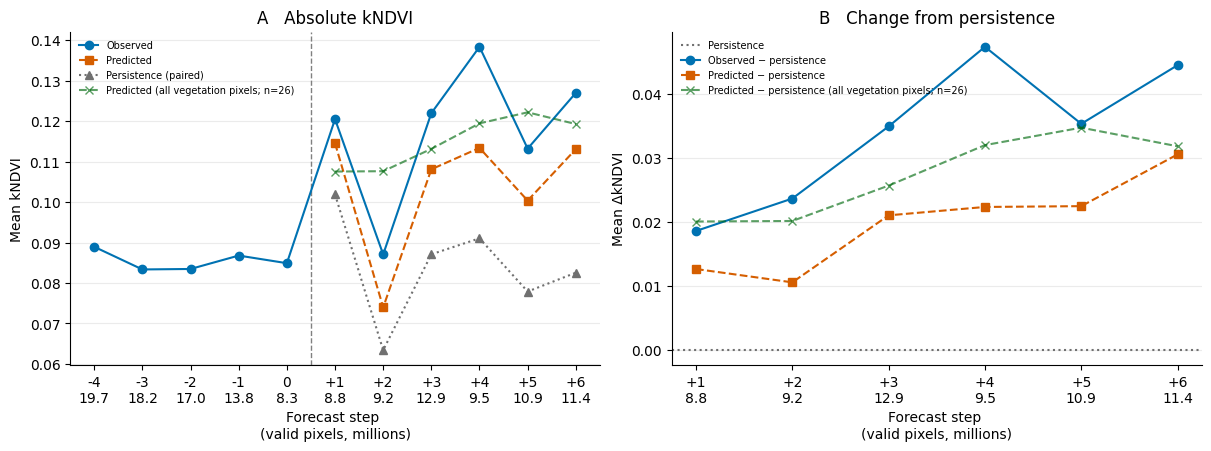

In [142]:
SAVE_FIGURES = False
SHOW_PREDICTED_ALL = True     # additional red curve in A showing predicted on all pixels (not just observed)
ERROR = "sd"                  # None, "sd" oder "se": Deviation/SE between cubes
ERROR_FOR = {"observed", "predicted", "delta_obs", "delta_pred"}


pixel_summary = (detail.loc[detail.n_pixels.gt(0)]
                 .groupby(["step", "curve"], as_index=False)
                 .agg(total=("total", "sum"), n_pixels=("n_pixels", "sum"), n_cubes=("cube_id", "nunique")))
extra = []
if SHOW_PREDICTED_ALL:
    extra.append("predicted_all")

pixel_summary["mean"] = pixel_summary["total"] / pixel_summary["n_pixels"]
fig_pixel = plot_panels(pixel_summary, extra=extra, error=ERROR,
                       error_for=ERROR_FOR)

## Cube weighted analysis

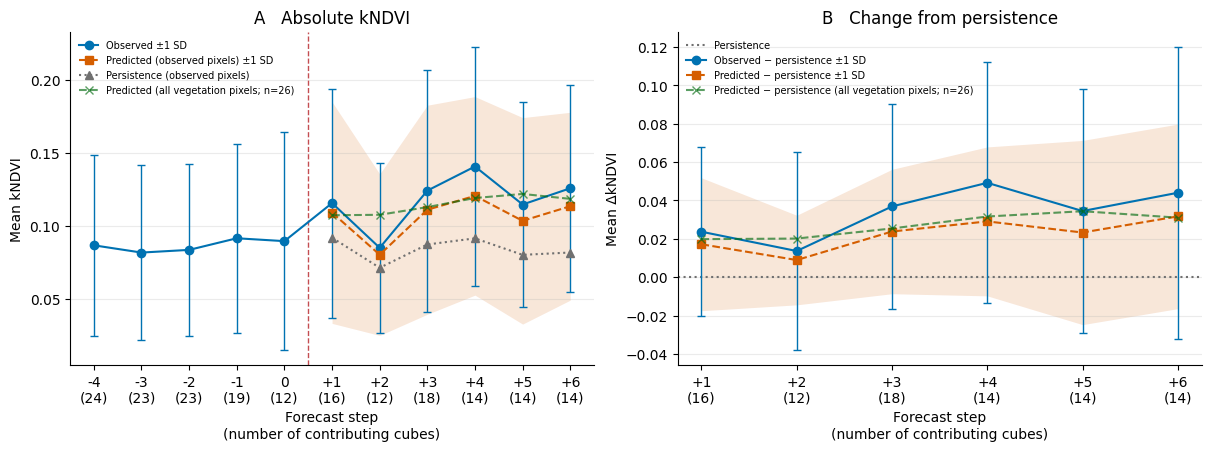

In [ ]:
APPLY_SLICE_FILTER = True     # whether to apply eligibility filter (only for cube-level plots)
SHOW_PERSISTENCE = True       # show persistence curve on observed pixels
SHOW_PREDICTED_ALL = True     # additional red curve in A showing predicted on all pixels (not just observed)
SHOW_PERSISTENCE_ALL = False
SHOW_CUBES = False            # showing well-observed individual cubes in the background of A
ERROR = "sd"                  # None, "sd" oder "se": Deviation/SE between cubes
ERROR_FOR = {"observed", "predicted", "delta_obs", "delta_pred"}


sample = detail.loc[detail.n_pixels.gt(0)]
if APPLY_SLICE_FILTER:
    sample = sample.loc[sample.eligible]   # _all-Zeilen sind unabhängig vom Target-Filter
cube_summary = (sample.groupby(["step", "curve"], as_index=False)
                .agg(mean=("cube_mean", "mean"), sd=("cube_mean", "std"),
                     n_cubes=("cube_id", "nunique"), n_pixels=("n_pixels", "sum")))

extra = []
if SHOW_PREDICTED_ALL:
    extra.append("predicted_all")
if SHOW_PERSISTENCE_ALL:
    extra.append("persistence_all")

background = None
if SHOW_CUBES:
    good = detail.loc[detail.curve.eq("observed") & detail.step.gt(0) & detail.eligible]
    complete = good.groupby("cube_id").step.nunique().eq(len(FUTURE))
    background = sample.loc[sample.cube_id.isin(complete.index[complete])
                            & sample.curve.isin(["observed", "predicted"])]
fig_cube = plot_panels(cube_summary, cube_weighted=True, extra=extra, error=ERROR,
                       error_for=ERROR_FOR, show_persistence=SHOW_PERSISTENCE, background=background, fig_name="_with_std_and_all")

### Quanitative

In [ ]:
curves = [
    "observed", "predicted", "persistence",        # Panel A: auf beobachteten Pixeln
    "predicted_all", "persistence_all",            # Panel A: unabhängig vom Target
    "delta_obs", "delta_pred",                     # Panel B: Änderung auf gepaarten Pixeln
    "delta_pred_all",                              # Panel B: falls bereits berechnet
]
curves = [c for c in curves if c in cube_summary["curve"].values]

means = (cube_summary.pivot(index="step", columns="curve", values="mean")
         .reindex(index=STEPS, columns=curves))

counts = (cube_summary.pivot(index="step", columns="curve", values="n_cubes")
          .reindex(index=STEPS, columns=curves).fillna(0).astype(int))

print("Cube-weighted mean kNDVI / change from persistence:")
print(means.to_string(float_format=lambda x: f"{x:.5f}", na_rep="–"))

# print("\nNumber of contributing cubes:")
# print(counts.to_string())

Cube-weighted mean kNDVI / change from persistence:
curve  observed  predicted  persistence  predicted_all  persistence_all  delta_obs  delta_pred  delta_pred_all
step                                                                                                          
-4      0.08664          –            –              –                –          –           –               –
-3      0.08167          –            –              –                –          –           –               –
-2      0.08351          –            –              –                –          –           –               –
-1      0.09147          –            –              –                –          –           –               –
 0      0.08951          –            –              –                –          –           –               –
 1      0.11559    0.10905      0.09186        0.10725          0.08740    0.02372     0.01718         0.01985
 2      0.08492    0.08021      0.07125        0.10757      

## Individual cube analysis

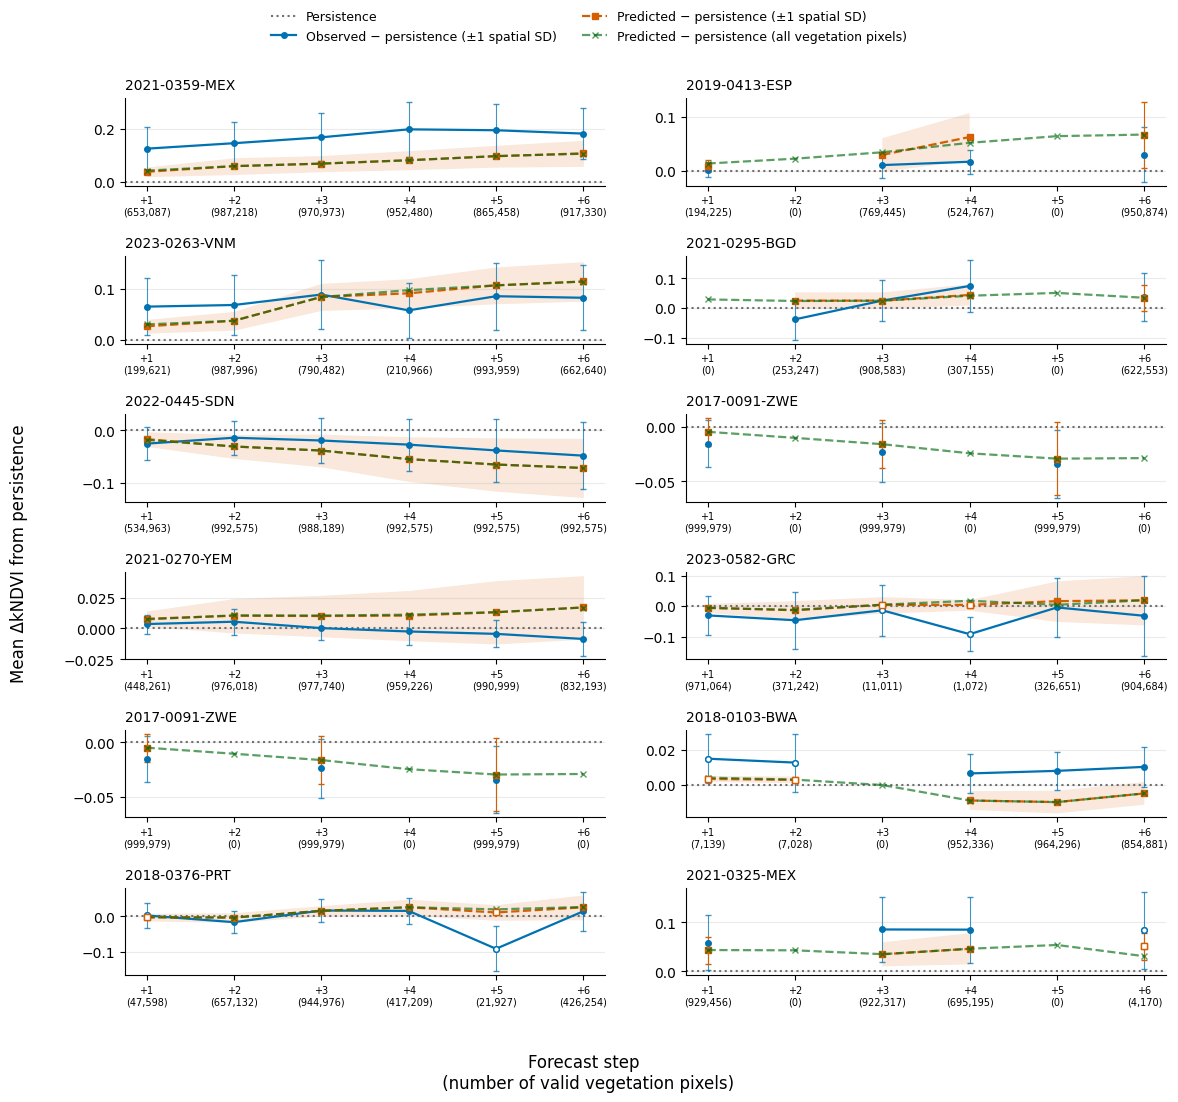

In [10]:
MODE = "relative"                         # "relative" oder "absolute"
SHOW_PREDICTED_ALL = True                 # optionale grüne Kurve
SHOW_SPATIAL_SD = True
SD_FOR = {"observed", "predicted"}        # optional zusätzlich: "predicted_all"
EXACT_COUNTS = True                       # False: z. B. 952k statt 952,480
SAVE_FiGURES = True

cube_ids = [
    "2021-0359-MEX", "2019-0413-ESP",
    "2023-0263-VNM", "2021-0295-BGD",
    "2022-0445-SDN", "2017-0091-ZWE",
    "2021-0270-YEM", "2023-0582-GRC",
    ################################
    "2017-0091-ZWE", "2018-0103-BWA",
    "2018-0376-PRT", "2021-0325-MEX",
    "2021-0429-PAK", "2021-0442-USA",
    "2022-0442-AFG",  "2022-0609-ITA"
]

relative = MODE == "relative"
steps = FUTURE if relative else STEPS
obs_key, pred_key, all_key = (("delta_obs", "delta_pred", "delta_pred_all") if relative
                              else ("observed", "predicted", "predicted_all"))
if SHOW_SPATIAL_SD and "spatial_sd" not in detail:
    raise ValueError("Bitte zuerst die aktualisierte read_cube-Zelle ausführen.")
domain = "all vegetation pixels" if VEG_ONLY else "all pixels"

def format_count(n):
    if EXACT_COUNTS or n < 1000:
        return f"{n:,}"
    return f"{n/1000:.1f}k" if n < 1_000_000 else f"{n/1_000_000:.2f}M"

def plot_cube(ax, cube_id):
    rows = detail.loc[detail["cube_id"].eq(cube_id)]
    if rows.empty:
        raise ValueError(f"Keine Daten für {cube_id}.")

    def series(key):
        return rows.loc[rows["curve"].eq(key)].set_index("step").reindex(steps)

    if relative:
        ax.axhline(0, color="#707070", ls=":", label="Persistence")
    else:
        ax.plot(steps, series("persistence")["cube_mean"], "^:", color="#707070",
                label="Persistence (observed pixels)")
        if N_CONTEXT:
            ax.axvline(0.5, color="0.5", ls="--", lw=1)

    label_pred = "Predicted − persistence" if relative else "Predicted"
    curves = [
        ("observed", obs_key, "Observed − persistence" if relative else "Observed", "#0072B2", "o-"),
        ("predicted", pred_key, label_pred if relative else "Predicted (observed pixels)", "#D55E00", "s--"),
    ]
    if SHOW_PREDICTED_ALL:
        if all_key not in rows["curve"].values:
            raise ValueError(f"{all_key} fehlt in detail.")
        curves.append(("predicted_all", all_key, f"{label_pred} ({domain})", "#036C11", "x--"))

    for name, key, label, color, style in curves:
        g = series(key)
        mean = g["cube_mean"].to_numpy(dtype=float)
        show_sd = SHOW_SPATIAL_SD and name in SD_FOR
        ax.plot(steps, mean, style, color=color, lw=1.6, ms=4, zorder=3,
                alpha=0.65 if name == "predicted_all" else 1,
                label=label + (" (±1 spatial SD)" if show_sd else ""))
        if show_sd:
            sd = g["spatial_sd"].to_numpy(dtype=float)
            ok = np.isfinite(mean) & np.isfinite(sd)
            if name == "observed":
                ax.errorbar(steps[ok], mean[ok], yerr=sd[ok], fmt="none",
                            ecolor=color, elinewidth=0.8, capsize=2, alpha=0.75, zorder=2)
            else:
                ax.fill_between(steps, mean-sd, mean+sd, where=ok,
                                color=color, alpha=0.14, lw=0, zorder=1)
                # Ein einzelner Punkt ohne direkte Nachbarn kann kein Band aufspannen.
                isolated = ok & ~np.r_[False, ok[:-1]] & ~np.r_[ok[1:], False]
                if isolated.any():
                    ax.errorbar(steps[isolated], mean[isolated], yerr=sd[isolated],
                                fmt="none", ecolor=color, elinewidth=0.8, capsize=2, zorder=2)

        if name != "predicted_all":
            low = g["eligible"].eq(False).to_numpy() & np.isfinite(mean)
            ax.plot(steps[low], mean[low], ls="none", marker=style[0], ms=4,
                    markerfacecolor="white", markeredgecolor=color, zorder=4)

    counts = series(obs_key)["n_pixels"].fillna(0).astype(int)
    ax.set_xticks(steps, [(f"{s:+d}" if s else "0") + f"\n({format_count(n)})"
                          for s, n in zip(steps, counts)])
    ax.tick_params(axis="x", labelsize=7)
    ax.set_title(cube_id, loc="left", fontsize=10)
    ax.grid(axis="y", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)

# Eigene x-Achse pro Panel, damit die Pixelzahlen nicht vom letzten Cube übernommen werden.
fig, axes = plt.subplots(6, 2, figsize=(12 if relative else 15, 11), sharex=False)
for ax, cube_id in zip(axes.flat, cube_ids):
    plot_cube(ax, cube_id)

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, fontsize=9, frameon=False)
fig.supylabel("Mean ΔkNDVI from persistence" if relative else "Mean kNDVI")
fig.supxlabel("Forecast step \n (number of valid vegetation pixels)" if relative
              else "Forecast step \n (number of valid vegetation observations)")
fig.tight_layout(rect=(0.025, 0.025, 1, 0.945), h_pad=1.4)

if SAVE_FIGURES:
    fig.savefig(OUTPUT / f"twelve_cubes_{MODE}_all_{SHOW_PREDICTED_ALL}_sd_{SHOW_SPATIAL_SD}.png",
                dpi=300, bbox_inches="tight")
plt.show()

## Per Landcover 

In [145]:
TIME_DIM = "time_sentinel_2_l2a"
LC_CLASSES = {
    10: "Tree cover", 20: "Shrubland", 30: "Grassland",
    40: "Cropland", 60: "Bare or sparse vegetation",
}

def landcover_cube_rows(cube_id, tensor_path):
    rows = []
    gate = rules.loc[cube_id].loc[FUTURE]
    with xr.open_zarr(SOURCE_DIR / f"{cube_id}_postprocessed.zarr", chunks=None) as src:
        cutoff = pd.Timestamp(src.attrs["precip_end_date"])
        ctx = src.sel({TIME_DIM: slice(None, cutoff)}).tail({TIME_DIM: MODEL_CONTEXT})
        if ctx.sizes[TIME_DIM] != MODEL_CONTEXT or pd.Timestamp(ctx[TIME_DIM].values[-1]) != cutoff:
            raise ValueError(f"{cube_id}: unvollständiger Modellkontext.")
        static = ctx.isel({TIME_DIM: -1})
        veg = static["is_veg"].transpose("y", "x").values > 0.5
        lc = static["ESA_LC"].transpose("y", "x").values
        masks = ctx["target_mask"].transpose(TIME_DIM, "y", "x").values > 0.5
        has_ref = masks.any(axis=0)
        if N_CONTEXT:
            history = ctx["kNDVI"].tail({TIME_DIM: N_CONTEXT}).transpose(TIME_DIM, "y", "x").values

    with xr.open_zarr(tensor_path, chunks=None) as ds:
        if ds.sizes["time"] != len(FUTURE):
            raise ValueError(f"{cube_id}: unerwartete Forecast-Länge.")
        obs, pred, base, target = [ds[k].transpose("time", "y", "x").values
                                   for k in ("true", "pred", "base", "mask")]
    valid_target = (target > 0.5) & veg & np.isfinite(obs)
    if not (np.isfinite(pred[valid_target]).all() and np.isfinite(base[valid_target]).all()):
        raise ValueError(f"{cube_id}: fehlende Vorhersage auf gültigem Target.")

    for code in LC_CLASSES:
        region = veg & (lc == code)
        size = int(region.sum())
        if not size:
            continue

        def eligible(n, rule):
            return n >= rule.min_count and n / size >= rule.min_coverage

        def add(step, name, values, use):
            if values.size:
                rows.append((cube_id, code, step, name, values.mean(dtype="float64"), values.size, use))

        if N_CONTEXT:
            for step, y, m in zip(range(1 - N_CONTEXT, 1), history, masks[-N_CONTEXT:]):
                ok = region & m & np.isfinite(y)
                add(step, "observed", y[ok], eligible(ok.sum(), gate.iloc[0]))

        for t, step in enumerate(FUTURE):
            ok = region & valid_target[t]
            use = eligible(ok.sum(), gate.loc[step])
            paired = ok & has_ref
            for name, frame in [("observed", obs[t]), ("predicted", pred[t]), ("persistence", base[t])]:
                add(step, name, frame[ok], use)
            for name, frame in [("delta_obs", obs[t]), ("delta_pred", pred[t])]:
                add(step, name, np.subtract(frame[paired], base[t][paired], dtype=np.float64), use)

            # Ganze vegetierte Fläche DIESER Klasse; keine Target-Maske.
            pred_ok = region & np.isfinite(pred[t])
            base_ok = region & np.isfinite(base[t])
            ref_ok = pred_ok & base_ok & has_ref
            add(step, "predicted_all", pred[t][pred_ok], True)
            add(step, "persistence_all", base[t][base_ok], True)
            add(step, "delta_pred_all", np.subtract(pred[t][ref_ok], base[t][ref_ok], dtype=np.float64), True)
    return rows


lc_detail_ab = pd.DataFrame(
    [row for cid, event in events.iterrows() for row in landcover_cube_rows(cid, event.tensor_path)],
    columns=["cube_id", "code", "step", "curve", "cube_mean", "n_pixels", "eligible"],
)

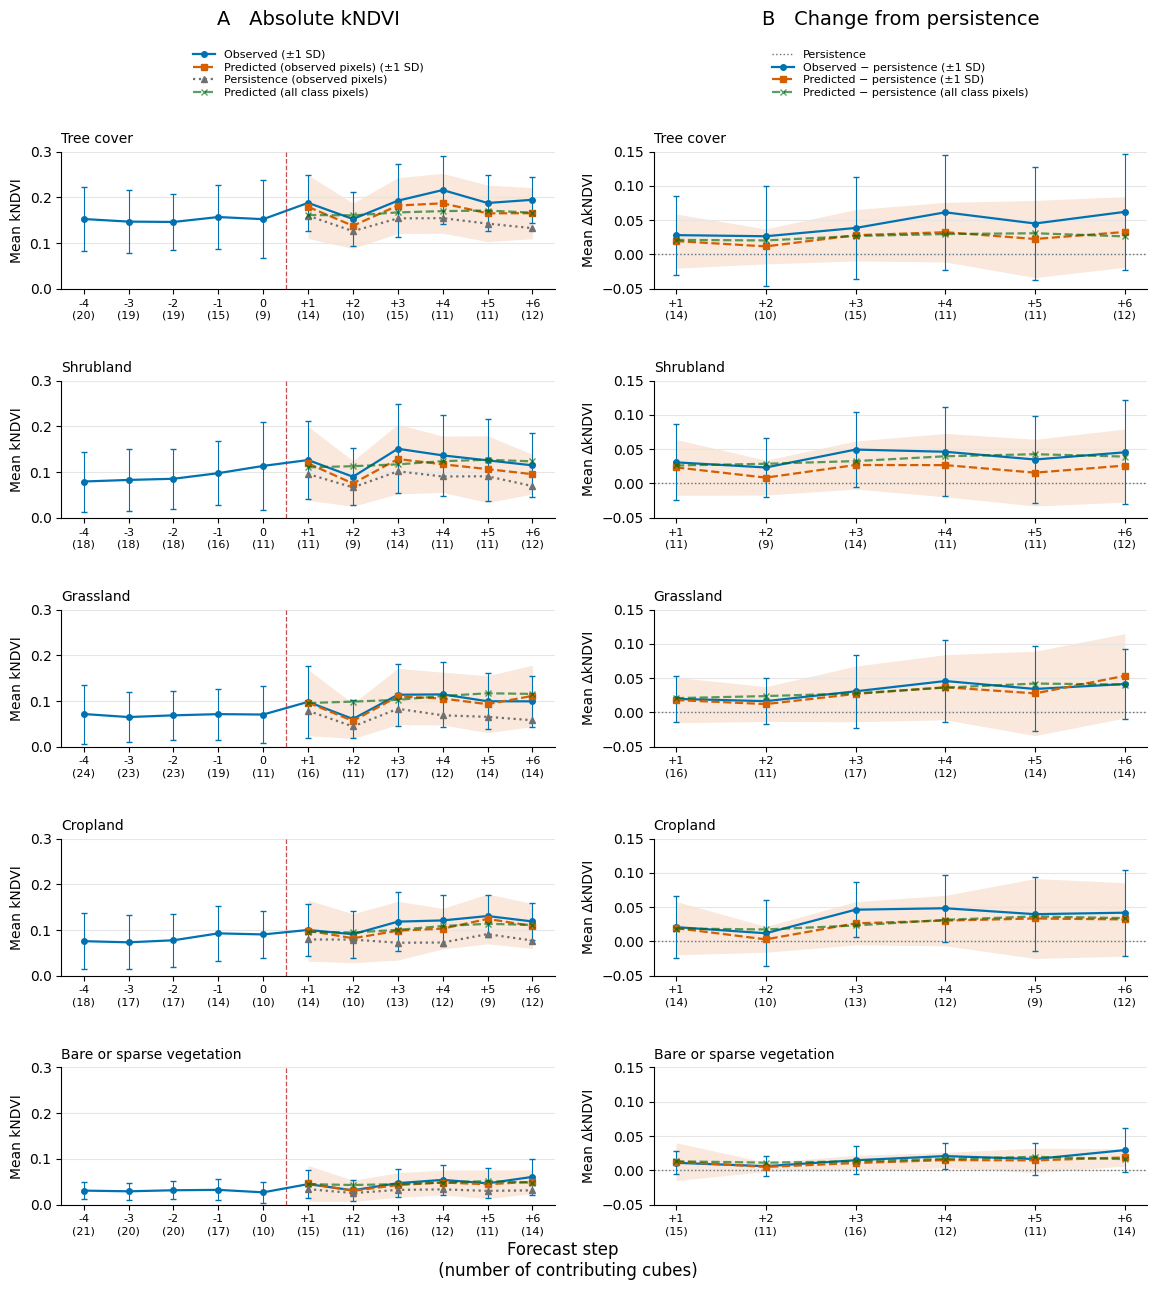

In [166]:
LC_SHOW_PERSISTENCE = True
LC_SHOW_PREDICTED_ALL = True           # grüne Zusatzkurve in A und B
LC_SHOW_PERSISTENCE_ALL = False        # optionale durchgezogene graue Kurve in A
LC_ERROR = "sd"                        # "sd", "se" oder None
LC_ERROR_FOR = {"Observed", "Predicted"}            # z. B. {"Observed", "Predicted"} für Balken + Band
LC_FILTER = True                      # False: bisherige LC-Auswahl, jeder Cube mit gültigen Pixeln
LC_SHOW_CUBES = False                  # dezente Hintergrundlinien: an allen Forecast-Schritten eligible
LC_SAVE = True

sample_lc = lc_detail_ab.loc[lc_detail_ab["eligible"]] if LC_FILTER else lc_detail_ab
lc_summary_ab = (sample_lc.groupby(["code", "step", "curve"], as_index=False)
                 .agg(mean=("cube_mean", "mean"), sd=("cube_mean", "std"),
                      n_cubes=("cube_id", "nunique"), n_pixels=("n_pixels", "sum")))
lc_summary_ab["se"] = lc_summary_ab.sd / np.sqrt(lc_summary_ab.n_cubes)


def draw_lc_row(a, b, code, name):
    group = lc_summary_ab.loc[lc_summary_ab.code.eq(code)]
    def series(key, steps):
        return group.loc[group.curve.eq(key)].set_index("step").reindex(steps)

    def line(ax, steps, key, role, label, color, style):
        g = series(key, steps)
        y = g["mean"].to_numpy(dtype=float)
        show_error = LC_ERROR in {"sd", "se"} and role in LC_ERROR_FOR
        suffix = f" (±1 {LC_ERROR.upper()})" if show_error else ""
        ax.plot(steps, y, style, color=color, label=label + suffix, lw=1.6, ms=4,
                alpha=0.65 if role == "Predicted (all)" else 1, zorder=3)
        if not show_error:
            return
        err = g[LC_ERROR].to_numpy(dtype=float)
        ok = np.isfinite(y) & np.isfinite(err)
        if role == "Observed":
            ax.errorbar(steps[ok], y[ok], yerr=err[ok], fmt="none", ecolor=color,
                        elinewidth=0.8, capsize=2.5, zorder=2)
        else:
            ax.fill_between(steps, y-err, y+err, where=ok, color=color, alpha=0.14, lw=0)
            isolated = ok & ~np.r_[False, ok[:-1]] & ~np.r_[ok[1:], False]
            if isolated.any():
                ax.errorbar(steps[isolated], y[isolated], yerr=err[isolated], fmt="none",
                            ecolor=color, elinewidth=0.8, capsize=2.5)

    if LC_SHOW_CUBES:
        candidates = lc_detail_ab.loc[lc_detail_ab.code.eq(code) & lc_detail_ab.step.gt(0)
                                       & lc_detail_ab.curve.eq("observed") & lc_detail_ab.eligible]
        complete = candidates.groupby("cube_id").step.nunique().eq(len(FUTURE))
        bg = sample_lc.loc[sample_lc.code.eq(code) & sample_lc.cube_id.isin(complete.index[complete])]
        for _, g in bg.groupby("cube_id"):
            for ax, keys, steps in [(a, ("observed","predicted"), STEPS),
                                    (b, ("delta_obs","delta_pred"), FUTURE)]:
                for key, color, ls in zip(keys, ("#0072B2","#D55E00"), ("-","--")):
                    yy = g.loc[g.curve.eq(key)].set_index("step").cube_mean.reindex(steps)
                    ax.plot(steps, yy, ls=ls, color=color, alpha=0.18, lw=0.8, zorder=1)

    line(a, STEPS, "observed", "Observed", "Observed", "#0072B2", "o-")
    line(a, FUTURE, "predicted", "Predicted", "Predicted (observed pixels)", "#D55E00", "s--")
    if LC_SHOW_PERSISTENCE:
        line(a, FUTURE, "persistence", "Persistence", "Persistence (observed pixels)", "#707070", "^:")
    if LC_SHOW_PERSISTENCE_ALL:
        line(a, FUTURE, "persistence_all", "Persistence (all)", "Persistence (all class pixels)", "#707070", "-")
    if N_CONTEXT:
        a.axvline(0.5, color="#C44E52", ls="--", lw=0.9)
    b.axhline(0, color="#707070", ls=":", lw=1, label="Persistence")
    line(b, FUTURE, "delta_obs", "Observed", "Observed − persistence", "#0072B2", "o-")
    line(b, FUTURE, "delta_pred", "Predicted", "Predicted − persistence", "#D55E00", "s--")
    if LC_SHOW_PREDICTED_ALL:
        line(a, FUTURE, "predicted_all", "Predicted (all)", "Predicted (all class pixels)", "#036C11", "x--")
        line(b, FUTURE, "delta_pred_all", "Predicted (all)", "Predicted − persistence (all class pixels)", "#036C11", "x--")
    a.set(ylim=(0, 0.30), ylabel="Mean kNDVI")
    b.set(ylim=(-0.05, 0.15), ylabel="Mean ΔkNDVI")        
    for ax, steps, key in [(a, STEPS, "observed"), (b, FUTURE, "delta_obs")]:
        counts = series(key, steps).n_cubes.fillna(0).astype(int)
        ax.set_xticks(steps, [(f"{s:+d}" if s else "0") + f"\n({n})" for s, n in zip(steps, counts)])
        ax.set_title(name, loc="left", fontsize=10)
        ax.tick_params(axis="x", labelsize=8)
        ax.spines[["top","right"]].set_visible(False)
        ax.grid(axis="y", color="0.90", lw=0.8)


fig_lc, axes_lc = plt.subplots(len(LC_CLASSES), 2, figsize=(12, 13), sharex=False, sharey=False)
for (a, b), (code, name) in zip(axes_lc, LC_CLASSES.items()):
    draw_lc_row(a, b, code, name)

fig_lc.subplots_adjust(left=0.08, right=0.985, bottom=0.07, top=0.88, hspace=0.67, wspace=0.20)
for j, title in enumerate(["A   Absolute kNDVI", "B   Change from persistence"]):
    ax = axes_lc[0, j]
    pos = ax.get_position()
    x = (pos.x0 + pos.x1) / 2
    fig_lc.text(x, 0.989, title, ha="center", va="top", fontsize=14)
    handles, labels = ax.get_legend_handles_labels()
    fig_lc.legend(handles, labels, loc="upper center", bbox_to_anchor=(x, 0.966),
                  ncol=1, frameon=False, fontsize=8, labelspacing=0.25)
fig_lc.supxlabel("Forecast step \n (number of contributing cubes)", y=0.012)
if LC_SAVE:
    folder = Path(OUTPUT) / "landcover_cube_weighted_trajectories"
    folder.mkdir(parents=True, exist_ok=True)
    fig_lc.savefig(folder / f"landcover_AB_filter_{LC_FILTER}_all_{LC_SHOW_PREDICTED_ALL}_{LC_ERROR}.png",
                   dpi=300, bbox_inches="tight")
plt.show()

## Per Climate class (First Köppen Geiger Letter)

In [157]:
CLIM_CLASSES = {"A": "Tropical", "B": "Arid", "C": "Temperate"}#, "D": "Continental", "E": "Polar"}
keys = ["cube_id", "step", "curve"]
cols = keys + ["cube_mean", "n_pixels", "eligible"]
if not set(cols).issubset(detail.columns) or detail.duplicated(keys).any():
    raise ValueError("detail muss aus der Ganzcube-read_cube-Zelle stammen, nicht aus einer Landcover-Tabelle.")

clim_meta = pd.read_csv(REPO / "data_processing" / "data" / "train_test_split.csv",
                        usecols=["DisNo.", "koppen_geiger"]).rename(columns={"DisNo.": "cube_id"})
clim_meta["climate"] = clim_meta["koppen_geiger"].astype("string").str.strip().str.upper().str[0]
clim_meta = clim_meta.loc[clim_meta.cube_id.isin(detail.cube_id), ["cube_id", "climate"]].drop_duplicates()
clim_detail = detail[cols].merge(clim_meta, on="cube_id", how="left", validate="many_to_one")
# missing = clim_detail.loc[~clim_detail.climate.isin(CLIM_CLASSES), "cube_id"].unique()
# if len(missing):
#     raise ValueError(f"Fehlende oder ungültige Klimaklasse: {', '.join(missing)}")

# Gesamtzahl im Run, separat von der Zahl mit gültigen Werten an einem bestimmten Schritt.
clim_totals = clim_detail.groupby("climate").cube_id.nunique().reindex(CLIM_CLASSES, fill_value=0)
print(clim_totals.rename("cubes_in_run").to_string())

climate
A     4
B    14
C     6


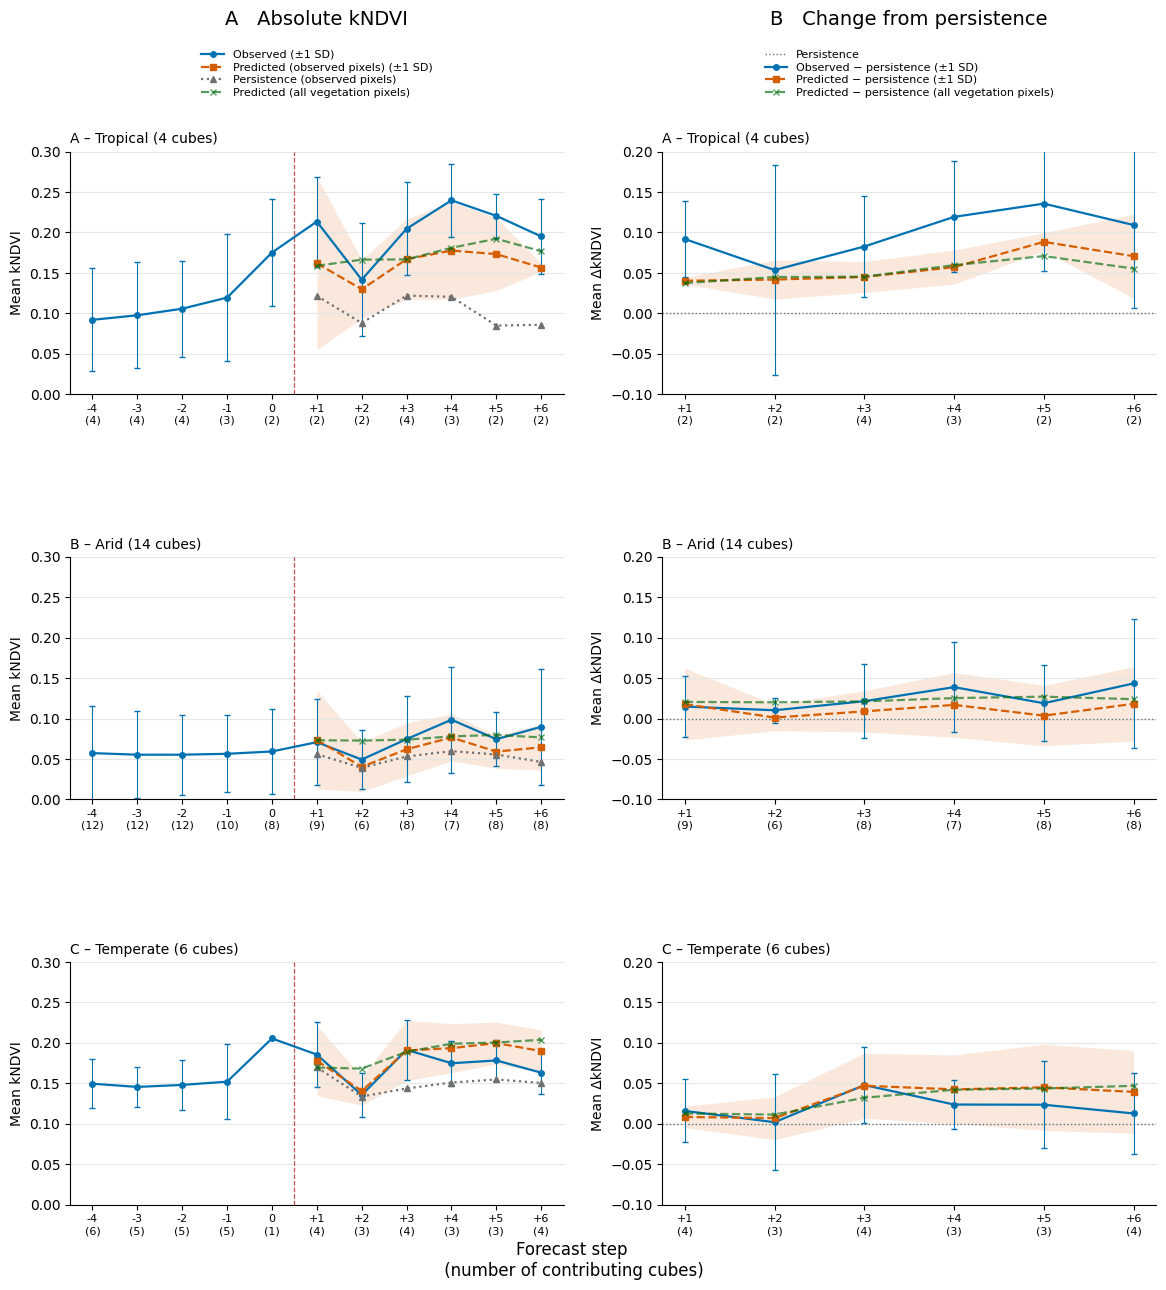

In [165]:
CLIM_SHOW_PERSISTENCE = True
CLIM_SHOW_PREDICTED_ALL = True           # grüne Zusatzkurve in A und B
CLIM_SHOW_PERSISTENCE_ALL = False        # optionale durchgezogene graue Kurve in A
CLIM_ERROR = "sd"                        # "sd", "se" oder None
CLIM_ERROR_FOR = {"Observed", "Predicted"}            # z. B. {"Observed", "Predicted"} für Balken + Band
CLIM_FILTER = True                      # False: jeder Cube mit nutzbaren Pixeln am jeweiligen Schritt
CLIM_SHOW_CUBES = False                  # dezente Hintergrundlinien: an allen Forecast-Schritten eligible
CLIM_SAVE = True

if CLIM_SHOW_PREDICTED_ALL and "delta_pred_all" not in clim_detail.curve.values:
    raise ValueError("Für die grüne Kurve in B: Ganzcube-read_cube mit delta_pred_all ausführen oder CLIM_SHOW_PREDICTED_ALL=False.")
clim_sample = clim_detail.loc[clim_detail.n_pixels.gt(0) & clim_detail.cube_mean.notna()]
if CLIM_FILTER:
    clim_sample = clim_sample.loc[clim_sample.eligible | clim_sample.curve.str.endswith("_all")]
domain = "all vegetation pixels" if VEG_ONLY else "all pixels"
clim_summary = (clim_sample.groupby(["climate", "step", "curve"], as_index=False)
                 .agg(mean=("cube_mean", "mean"), sd=("cube_mean", "std"),
                      n_cubes=("cube_id", "nunique"), n_pixels=("n_pixels", "sum")))
clim_summary["se"] = clim_summary.sd / np.sqrt(clim_summary.n_cubes)


def draw_climate_row(a, b, code, name):
    group = clim_summary.loc[clim_summary.climate.eq(code)]
    def series(key, steps):
        return group.loc[group.curve.eq(key)].set_index("step").reindex(steps)

    def line(ax, steps, key, role, label, color, style):
        g = series(key, steps)
        y = g["mean"].to_numpy(dtype=float)
        show_error = CLIM_ERROR in {"sd", "se"} and role in CLIM_ERROR_FOR
        suffix = f" (±1 {CLIM_ERROR.upper()})" if show_error else ""
        ax.plot(steps, y, style, color=color, label=label + suffix, lw=1.6, ms=4,
                alpha=0.65 if role == "Predicted (all)" else 1, zorder=3)
        if not show_error:
            return
        err = g[CLIM_ERROR].to_numpy(dtype=float)
        ok = np.isfinite(y) & np.isfinite(err)
        if role == "Observed":
            ax.errorbar(steps[ok], y[ok], yerr=err[ok], fmt="none", ecolor=color,
                        elinewidth=0.8, capsize=2.5, zorder=2)
        else:
            ax.fill_between(steps, y-err, y+err, where=ok, color=color, alpha=0.14, lw=0)
            isolated = ok & ~np.r_[False, ok[:-1]] & ~np.r_[ok[1:], False]
            if isolated.any():
                ax.errorbar(steps[isolated], y[isolated], yerr=err[isolated], fmt="none",
                            ecolor=color, elinewidth=0.8, capsize=2.5)

    if CLIM_SHOW_CUBES:
        candidates = clim_detail.loc[clim_detail.climate.eq(code) & clim_detail.step.gt(0)
                                       & clim_detail.curve.eq("observed") & clim_detail.eligible & clim_detail.n_pixels.gt(0)]
        complete = candidates.groupby("cube_id").step.nunique().eq(len(FUTURE))
        bg = clim_sample.loc[clim_sample.climate.eq(code) & clim_sample.cube_id.isin(complete.index[complete])]
        for _, g in bg.groupby("cube_id"):
            for ax, keys, steps in [(a, ("observed","predicted"), STEPS),
                                    (b, ("delta_obs","delta_pred"), FUTURE)]:
                for key, color, ls in zip(keys, ("#0072B2","#D55E00"), ("-","--")):
                    yy = g.loc[g.curve.eq(key)].set_index("step").cube_mean.reindex(steps)
                    ax.plot(steps, yy, ls=ls, color=color, alpha=0.18, lw=0.8, zorder=1)

    line(a, STEPS, "observed", "Observed", "Observed", "#0072B2", "o-")
    line(a, FUTURE, "predicted", "Predicted", "Predicted (observed pixels)", "#D55E00", "s--")
    if CLIM_SHOW_PERSISTENCE:
        line(a, FUTURE, "persistence", "Persistence", "Persistence (observed pixels)", "#707070", "^:")
    if CLIM_SHOW_PERSISTENCE_ALL:
        line(a, FUTURE, "persistence_all", "Persistence (all)", f"Persistence ({domain})", "#707070", "-")
    if N_CONTEXT:
        a.axvline(0.5, color="#C44E52", ls="--", lw=0.9)
    b.axhline(0, color="#707070", ls=":", lw=1, label="Persistence")
    line(b, FUTURE, "delta_obs", "Observed", "Observed − persistence", "#0072B2", "o-")
    line(b, FUTURE, "delta_pred", "Predicted", "Predicted − persistence", "#D55E00", "s--")
    if CLIM_SHOW_PREDICTED_ALL:
        line(a, FUTURE, "predicted_all", "Predicted (all)", f"Predicted ({domain})", "#036C11", "x--")
        line(b, FUTURE, "delta_pred_all", "Predicted (all)", f"Predicted − persistence ({domain})", "#036C11", "x--")
    a.set(ylim=(0, 0.30), ylabel="Mean kNDVI")
    b.set(ylim=(-0.10, 0.20), ylabel="Mean ΔkNDVI")        # unabhängige y-Skala pro Klimaklasse
    for ax, steps, key in [(a, STEPS, "observed"), (b, FUTURE, "delta_obs")]:
        counts = series(key, steps).n_cubes.fillna(0).astype(int)
        ax.set_xticks(steps, [(f"{s:+d}" if s else "0") + f"\n({n})" for s, n in zip(steps, counts)])
        total = clim_totals.at[code]
        ax.set_title(f"{code} – {name} ({total} {'cube' if total == 1 else 'cubes'})", loc="left", fontsize=10)
        ax.tick_params(axis="x", labelsize=8)
        ax.spines[["top","right"]].set_visible(False)
        ax.grid(axis="y", color="0.90", lw=0.8)


fig_clim, axes_clim = plt.subplots(len(CLIM_CLASSES), 2, figsize=(12, 13), sharex=False, sharey=False)
for (a, b), (code, name) in zip(axes_clim, CLIM_CLASSES.items()):
    draw_climate_row(a, b, code, name)

fig_clim.subplots_adjust(left=0.08, right=0.985, bottom=0.07, top=0.88, hspace=0.67, wspace=0.20)
for j, title in enumerate(["A   Absolute kNDVI", "B   Change from persistence"]):
    ax = axes_clim[0, j]
    pos = ax.get_position()
    x = (pos.x0 + pos.x1) / 2
    fig_clim.text(x, 0.989, title, ha="center", va="top", fontsize=14)
    handles, labels = ax.get_legend_handles_labels()
    fig_clim.legend(handles, labels, loc="upper center", bbox_to_anchor=(x, 0.966),
                  ncol=1, frameon=False, fontsize=8, labelspacing=0.25)
fig_clim.supxlabel("Forecast step \n (number of contributing cubes) ", y=0.012)
if CLIM_SAVE:
    folder = Path(OUTPUT) / "climate_cube_weighted_trajectories"
    folder.mkdir(parents=True, exist_ok=True)
    fig_clim.savefig(folder / f"climate_AB_filter_{CLIM_FILTER}_all_{CLIM_SHOW_PREDICTED_ALL}_{CLIM_ERROR}.png",
                   dpi=300, bbox_inches="tight")
plt.show()